# Modelos Tabulares

### imports

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, recall_score, classification_report

### Importar e tratar dados


In [30]:
# Carregar features estáticas por evento
df = pd.read_csv("../csv/train_data_features.csv")
X = df.drop(columns=["event_id", "risk"])
y = (df["risk"] >= -6).astype(int)

# Tratar infinitos e NaNs
X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median())

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Escalonamento para modelos sensíveis à escala
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Armazenar modelos e métricas
models = {}
results = {}


### 1- Logistic Regression

In [31]:
# 1) Logistic Regression
lr = LogisticRegression(class_weight='balanced', max_iter=1000)
lr.fit(X_train_scaled, y_train)
models['LogisticRegression'] = (lr, X_test_scaled)
pred_lr = lr.predict(X_test_scaled)
results['LogisticRegression'] = {
    'accuracy': accuracy_score(y_test, pred_lr),
    'recall':   recall_score(y_test, pred_lr)
}

### 2- Random Forest

In [32]:
# 2) Random Forest
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
models['RandomForest'] = (rf, X_test)
pred_rf = rf.predict(X_test)
results['RandomForest'] = {
    'accuracy': accuracy_score(y_test, pred_rf),
    'recall':   recall_score(y_test, pred_rf)
}

### 3- XGBoost

In [33]:
# 3) XGBoost
scale_pos_weight = np.bincount(y_train)[0] / np.bincount(y_train)[1]
xgb_clf = xgb.XGBClassifier(
    n_estimators=100,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)
xgb_clf.fit(X_train, y_train)
models['XGBoost'] = (xgb_clf, X_test)
pred_xgb = xgb_clf.predict(X_test)
results['XGBoost'] = {
    'accuracy': accuracy_score(y_test, pred_xgb),
    'recall':   recall_score(y_test, pred_xgb)
}


c:\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [20:59:51] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


### 4 - Feedforward Neural Network(FNN's)

In [34]:
# 4) Feedforward Neural Network
fnn = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])
fnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', 'Recall'])
estop = EarlyStopping(patience=5, restore_best_weights=True)
history = fnn.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[estop],
    verbose=0
)
pred_prob = fnn.predict(X_test_scaled).ravel()
pred_nn   = (pred_prob > 0.5).astype(int)
models['FNN'] = (fnn, X_test_scaled)
results['FNN'] = {
    'accuracy': accuracy_score(y_test, pred_nn),
    'recall':   recall_score(y_test, pred_nn)
}


68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


## Resultados dos modelos

In [35]:
# 5) Printar resultados
print("Model performance (accuracy, recall):")
for name, metrics in results.items():
    print(f"{name:20s}: {metrics}")

# 6) Melhor modelo por recall
default_best = max(results, key=lambda k: results[k]['recall'])
print(f"\nBest model by recall: {default_best}\n")
mdl, X_eval = models[default_best]
if default_best == 'FNN':
    y_pred = (mdl.predict(X_eval).ravel() > 0.5).astype(int)
else:
    y_pred = mdl.predict(X_eval)
print(classification_report(y_test, y_pred))

Model performance (accuracy, recall):
LogisticRegression  : {'accuracy': 0.9155060352831941, 'recall': 0.9310344827586207}
RandomForest        : {'accuracy': 0.9953574744661096, 'recall': 0.8793103448275862}
XGBoost             : {'accuracy': 0.9944289693593314, 'recall': 0.9482758620689655}
FNN                 : {'accuracy': 0.9962859795728877, 'recall': 0.9310344827586207}

Best model by recall: XGBoost

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2096
           1       0.86      0.95      0.90        58

    accuracy                           0.99      2154
   macro avg       0.93      0.97      0.95      2154
weighted avg       0.99      0.99      0.99      2154



### Tabela de Parametros

In [37]:
# 7) Hiperparâmetros do FNN
# 7) Hiperparâmetros do FNN em formato de tabela
# 7) Hiperparâmetros do FNN em formato de tabela
param_df = pd.DataFrame({
    'Parameter': [
        'Layers', 'Neurons', 'Activation', 'Regularizer',
        'Optimizer', 'Batch Size', 'Epochs', 'Scaler', 'Class weights'
    ],
    'Value': [
        'Dense(64) -> Dropout(0.3) -> Dense(32) -> Dropout(0.2) -> Output',
        '64-32-1',
        'ReLU (hidden), Sigmoid (output)',
        'None (Dropout used)',
        'Adam',
        '32',
        '50 (EarlyStopping patience=5)',
        'StandardScaler',
        'balanced'
    ]
})
print("FNN Hyperparameters:")
print(param_df.to_string(index=False))

FNN Hyperparameters:
    Parameter                                                            Value
       Layers Dense(64) -> Dropout(0.3) -> Dense(32) -> Dropout(0.2) -> Output
      Neurons                                                          64-32-1
   Activation                                  ReLU (hidden), Sigmoid (output)
  Regularizer                                              None (Dropout used)
    Optimizer                                                             Adam
   Batch Size                                                               32
       Epochs                                    50 (EarlyStopping patience=5)
       Scaler                                                   StandardScaler
Class weights                                                         balanced


## Loss e accuracy

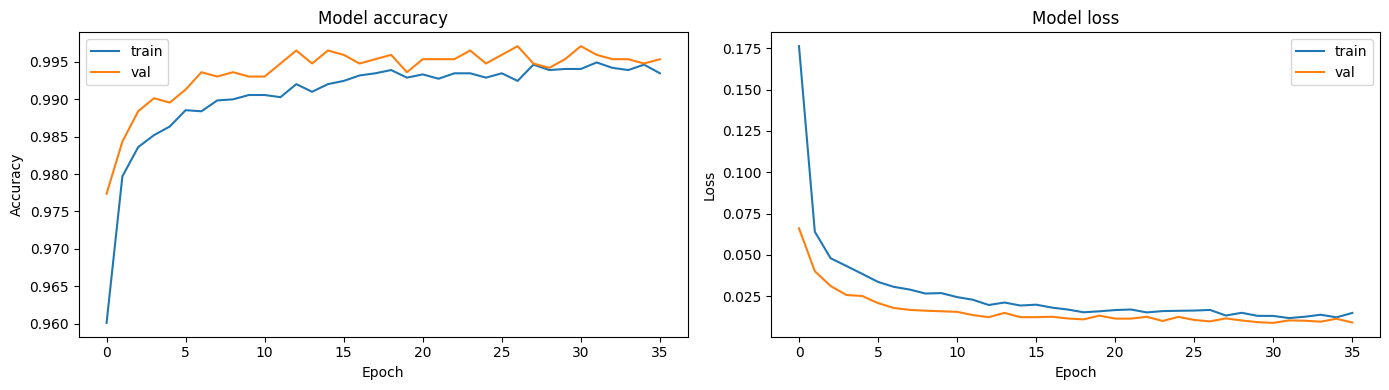

In [38]:
# 8) Plot de treinamento vs validação (acurácia e loss)
fig, axes = plt.subplots(1, 2, figsize=(14,4))
# acurácia
acc = history.history.get('accuracy', history.history.get('acc'))
val_acc = history.history.get('val_accuracy', history.history.get('val_acc'))
axes[0].plot(acc,    label='train')
axes[0].plot(val_acc, label='val')
axes[0].set_title('Model accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
# loss
loss = history.history['loss']
val_loss = history.history['val_loss']
axes[1].plot(loss,    label='train')
axes[1].plot(val_loss, label='val')
axes[1].set_title('Model loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
plt.tight_layout()
plt.show()
